# 04 — Exhaustive search of the 7 shortlisted proteins

With seven shortlisted proteins, every non-empty subset can be tested:

**2⁷ − 1 = 127 combinations**

Each combination is trained on `TrainData.csv` and evaluated on `TestData.csv` using accuracy, F1, sensitivity, specificity and ROC AUC.

The final selected panel is:

**NPX_GDF15 + NPX_SFTPB + NPX_WFDC2**

In [1]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

TRAIN_FILENAME = "TrainData.csv"
TEST_FILENAME = "TestData.csv"
TARGET = "clinic_group"
RANDOM_STATE = 42

PROTEINS = [
    "NPX_GDF15",
    "NPX_SFTPB",
    "NPX_MMP7",
    "NPX_FGA2242",
    "NPX_VCAM1",
    "NPX_WFDC2",
    "NPX_AREG",
]

FINAL_PANEL = ("NPX_GDF15", "NPX_SFTPB", "NPX_WFDC2")

HEALTHY_GROUPS = {"Healthy_control", "Non_stable_fibrotic_ILA"}
UNHEALTHY_GROUPS = {"Stable_fibrotic_ILA", "Progressive_ILA", "Established_ILD"}

def resolve_data_file(filename):
    for path in [Path("data") / filename, Path(filename)]:
        if path.exists():
            return path
    raise FileNotFoundError(
        f"Could not find {filename}. Put the authorized file in ./data/ "
        "or next to this notebook. Do not commit it to GitHub."
    )

def encode_target(series):
    mapping = {
        **{g: 0 for g in HEALTHY_GROUPS},
        **{g: 1 for g in UNHEALTHY_GROUPS},
    }
    unexpected = set(series.dropna().astype(str).unique()) - set(mapping)
    if unexpected:
        raise ValueError(f"Unexpected clinic_group values: {sorted(unexpected)}")
    return series.astype(str).map(mapping).to_numpy()

train = pd.read_csv(resolve_data_file(TRAIN_FILENAME))
test = pd.read_csv(resolve_data_file(TEST_FILENAME))
train.columns = train.columns.astype(str).str.strip()
test.columns = test.columns.astype(str).str.strip()

for name, data in [("train", train), ("test", test)]:
    missing = [c for c in [TARGET] + PROTEINS if c not in data.columns]
    if missing:
        raise ValueError(f"Missing columns in {name}: {missing}")

y_train = encode_target(train[TARGET])
y_test = encode_target(test[TARGET])


In [2]:
def build_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value=-6)),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=4000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ])

def evaluate_combination(combo):
    features = list(combo)
    X_train = train[features].apply(pd.to_numeric, errors="coerce")
    X_test = test[features].apply(pd.to_numeric, errors="coerce")

    model = build_model()
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    fpr, tpr, _ = roc_curve(y_test, prob)

    return {
        "Proteins_Tuple": tuple(combo),
        "Proteins": " + ".join(combo),
        "N_Proteins": len(combo),
        "Accuracy": accuracy_score(y_test, pred),
        "F1_UNHEALTHY": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "Sensitivity_UNHEALTHY": tp / (tp + fn),
        "Specificity_HEALTHY": tn / (tn + fp),
        "ROC_AUC": roc_auc_score(y_test, prob),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "FPR": fpr,
        "TPR": tpr,
    }

all_combinations = [
    combo
    for size in range(1, len(PROTEINS) + 1)
    for combo in combinations(PROTEINS, size)
]

assert len(all_combinations) == 127

results = [evaluate_combination(combo) for combo in all_combinations]
AllResults = pd.DataFrame([
    {k: v for k, v in row.items() if k not in {"FPR", "TPR"}}
    for row in results
])

print(f"Evaluated {len(AllResults)} combinations.")


Evaluated 127 combinations.


In [3]:
def top_table(metric, n=10):
    tie_breakers = {
        "Sensitivity_UNHEALTHY": ["ROC_AUC", "Specificity_HEALTHY"],
        "Specificity_HEALTHY": ["ROC_AUC", "Sensitivity_UNHEALTHY"],
        "ROC_AUC": ["Sensitivity_UNHEALTHY", "Specificity_HEALTHY"],
    }[metric]

    return (
        AllResults
        .sort_values(
            [metric, *tie_breakers, "N_Proteins", "Proteins"],
            ascending=[False, False, False, True, True],
        )
        .head(n)
        .reset_index(drop=True)
    )

columns = [
    "Proteins",
    "N_Proteins",
    "Sensitivity_UNHEALTHY",
    "Specificity_HEALTHY",
    "ROC_AUC",
    "Accuracy",
    "F1_UNHEALTHY",
]

print("Top 10 by sensitivity")
display(top_table("Sensitivity_UNHEALTHY")[columns])

print("Top 10 by specificity")
display(top_table("Specificity_HEALTHY")[columns])

print("Top 10 by ROC AUC")
display(top_table("ROC_AUC")[columns])


Top 10 by sensitivity


,Proteins,N_Proteins,Sensitivity_UNHEALTHY,Specificity_HEALTHY,ROC_AUC,Accuracy,F1_UNHEALTHY
0,NPX_GDF15 + NPX_SFTPB + NPX_FGA2242 + NPX_WFDC...,5,0.792308,0.828571,0.853297,0.805,0.840816
1,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,6,0.784615,0.814286,0.866593,0.795,0.832653
2,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_WFDC2 +...,5,0.784615,0.814286,0.863297,0.795,0.832653
3,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_VCAM1 +...,6,0.784615,0.814286,0.855385,0.795,0.832653
4,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,5,0.776923,0.814286,0.861648,0.790,0.827869
5,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,6,0.776923,0.814286,0.851978,0.790,0.827869
6,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,5,0.776923,0.814286,0.849670,0.790,0.827869
7,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_VCAM1 +...,5,0.776923,0.828571,0.849011,0.795,0.831276
8,NPX_GDF15 + NPX_SFTPB + NPX_WFDC2 + NPX_AREG,4,0.776923,0.800000,0.847912,0.785,0.824490
9,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,7,0.769231,0.828571,0.858791,0.790,0.826446


Top 10 by specificity


,Proteins,N_Proteins,Sensitivity_UNHEALTHY,Specificity_HEALTHY,ROC_AUC,Accuracy,F1_UNHEALTHY
0,NPX_GDF15 + NPX_SFTPB + NPX_WFDC2,3,0.753846,0.857143,0.841429,0.790,0.823529
1,NPX_GDF15 + NPX_SFTPB + NPX_FGA2242 + NPX_WFDC2,4,0.769231,0.842857,0.847143,0.795,0.829876
2,NPX_GDF15 + NPX_MMP7 + NPX_FGA2242 + NPX_VCAM1...,6,0.738462,0.842857,0.840330,0.775,0.810127
3,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,7,0.769231,0.828571,0.858791,0.790,0.826446
4,NPX_GDF15 + NPX_SFTPB + NPX_FGA2242 + NPX_WFDC...,5,0.792308,0.828571,0.853297,0.805,0.840816
5,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_VCAM1 +...,5,0.776923,0.828571,0.849011,0.795,0.831276
6,NPX_GDF15 + NPX_SFTPB + NPX_VCAM1 + NPX_WFDC2 ...,5,0.769231,0.828571,0.842418,0.790,0.826446
7,NPX_GDF15 + NPX_SFTPB + NPX_FGA2242 + NPX_VCAM...,5,0.769231,0.828571,0.840220,0.790,0.826446
8,NPX_GDF15 + NPX_SFTPB + NPX_VCAM1 + NPX_WFDC2,4,0.761538,0.828571,0.834725,0.785,0.821577
9,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,6,0.784615,0.814286,0.866593,0.795,0.832653


Top 10 by ROC AUC


,Proteins,N_Proteins,Sensitivity_UNHEALTHY,Specificity_HEALTHY,ROC_AUC,Accuracy,F1_UNHEALTHY
0,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,6,0.784615,0.814286,0.866593,0.795,0.832653
1,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_WFDC2 +...,5,0.784615,0.814286,0.863297,0.795,0.832653
2,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,5,0.776923,0.814286,0.861648,0.790,0.827869
3,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,7,0.769231,0.828571,0.858791,0.790,0.826446
4,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_WFDC2,4,0.761538,0.814286,0.857802,0.780,0.818182
5,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_VCAM1 +...,6,0.784615,0.814286,0.855385,0.795,0.832653
6,NPX_GDF15 + NPX_SFTPB + NPX_FGA2242 + NPX_WFDC...,5,0.792308,0.828571,0.853297,0.805,0.840816
7,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,6,0.776923,0.814286,0.851978,0.790,0.827869
8,NPX_GDF15 + NPX_MMP7 + NPX_FGA2242 + NPX_WFDC2...,5,0.738462,0.771429,0.850000,0.750,0.793388
9,NPX_GDF15 + NPX_SFTPB + NPX_MMP7 + NPX_FGA2242...,5,0.776923,0.814286,0.849670,0.790,0.827869


In [4]:
final_row = AllResults[
    AllResults["Proteins_Tuple"].apply(lambda x: tuple(x) == FINAL_PANEL)
].iloc[0]

display(
    final_row[
        [
            "Proteins",
            "N_Proteins",
            "Accuracy",
            "F1_UNHEALTHY",
            "Sensitivity_UNHEALTHY",
            "Specificity_HEALTHY",
            "ROC_AUC",
        ]
    ].to_frame("Value")
)


,Value
Proteins,NPX_GDF15 + NPX_SFTPB + NPX_WFDC2
N_Proteins,3
Accuracy,0.79
F1_UNHEALTHY,0.823529
Sensitivity_UNHEALTHY,0.753846
Specificity_HEALTHY,0.857143
ROC_AUC,0.841429


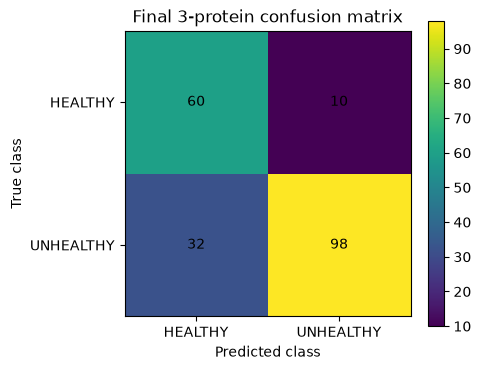

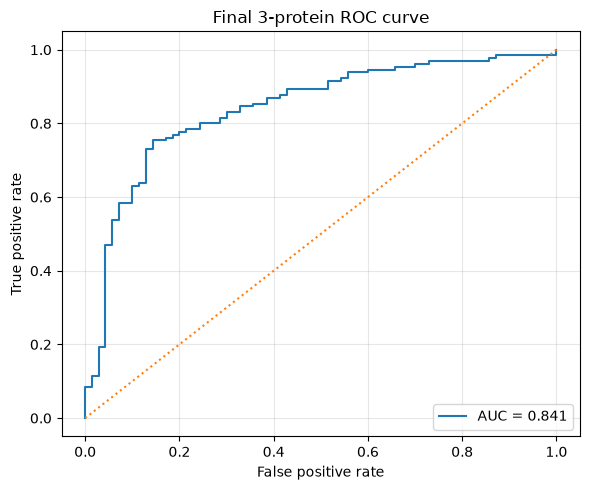

In [5]:
final_result = next(
    row for row in results
    if row["Proteins_Tuple"] == FINAL_PANEL
)

cm = np.array([
    [final_result["TN"], final_result["FP"]],
    [final_result["FN"], final_result["TP"]],
])

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("Final 3-protein confusion matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks([0, 1], labels=["HEALTHY", "UNHEALTHY"])
ax.set_yticks([0, 1], labels=["HEALTHY", "UNHEALTHY"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")

fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.plot(
    final_result["FPR"],
    final_result["TPR"],
    label=f"AUC = {final_result['ROC_AUC']:.3f}",
)
plt.plot([0, 1], [0, 1], linestyle=":")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Final 3-protein ROC curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Why the 3-protein model was selected

Some larger combinations achieved slightly higher sensitivity or ROC AUC. The **GDF15 + SFTPB + WFDC2** panel was nevertheless selected because:

1. it ranked **first for specificity**;
2. its overall sensitivity, F1, accuracy and ROC AUC remained competitive;
3. measuring three proteins is operationally simpler and potentially cheaper than measuring larger panels.

Specificity is the proportion of truly **HEALTHY** participants correctly classified as HEALTHY. Higher specificity therefore reduces false positives. In a hypothetical workflow where an UNHEALTHY prediction could trigger additional treatment or testing, fewer false positives could reduce unnecessary interventions and associated costs.

This project did **not** evaluate actual treatment outcomes or economic cost-effectiveness, so that last point is an operational motivation rather than a clinical/economic claim.